# Hands-on 22: Evaluasi Baseline Model pada Data Nyata vs Sintetik

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 7.

Dua baseline sederhana:
- Klasifikasi: Logistic Regression (dengan StandardScaler) pada `classification_room`.
- Regresi: Linear Regression pada `regression_energy` (MAE/RMSE + test_predictions.csv).

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Baseline Klasifikasi (Logistic Regression)

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/evaluate_baseline_classification.py"], capture_output=True, text=True)
print(r.stdout)

=== HASIL VALIDASI KLASIFIKASI ===
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

Confusion Matrix:
[[307   0]
 [  0  17]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       307
           1       1.00      1.00      1.00        17

    accuracy                           1.00       324
   macro avg       1.00      1.00      1.00       324
weighted avg       1.00      1.00      1.00       324


=== HASIL TEST KLASIFIKASI ===
Accuracy : 0.9907407407407407
Precision: 1.0
Recall   : 0.8421052631578947
F1 Score : 0.9142857142857143

Confusion Matrix:
[[305   0]
 [  3  16]]



## 2. Baseline Regresi (Linear Regression)

In [3]:
r = subprocess.run([sys.executable, "scripts/evaluate_baseline_regression.py"], capture_output=True, text=True)
print(r.stdout)

=== HASIL VALIDASI REGRESI ===
MAE : 16.008005111154723
RMSE: 23.480113312283923

=== HASIL TEST REGRESI ===
MAE : 17.304486633036102
RMSE: 27.200182439384985

[SUKSES] Prediksi test disimpan ke: data/processed/regression_energy/test_predictions.csv



## 3. Visualisasi Prediksi vs Aktual (Regresi)

In [4]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd

pred = pd.read_csv("data/processed/regression_energy/test_predictions.csv")
plt.figure(figsize=(12, 4))
plt.plot(pred["actual"].values[:200], label="aktual", lw=1.2)
plt.plot(pred["predicted"].values[:200], label="prediksi", lw=1.2, ls="--")
plt.title("Baseline Linear Regression - 200 Titik Test Pertama")
plt.xlabel("Indeks titik test")
plt.ylabel("Daya (watt)")
plt.legend()
plt.tight_layout()
Path("outputs/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("outputs/figures/baseline_regression_pred.png")
plt.show()
print("[SUKSES] outputs/figures/baseline_regression_pred.png")

[SUKSES] outputs/figures/baseline_regression_pred.png


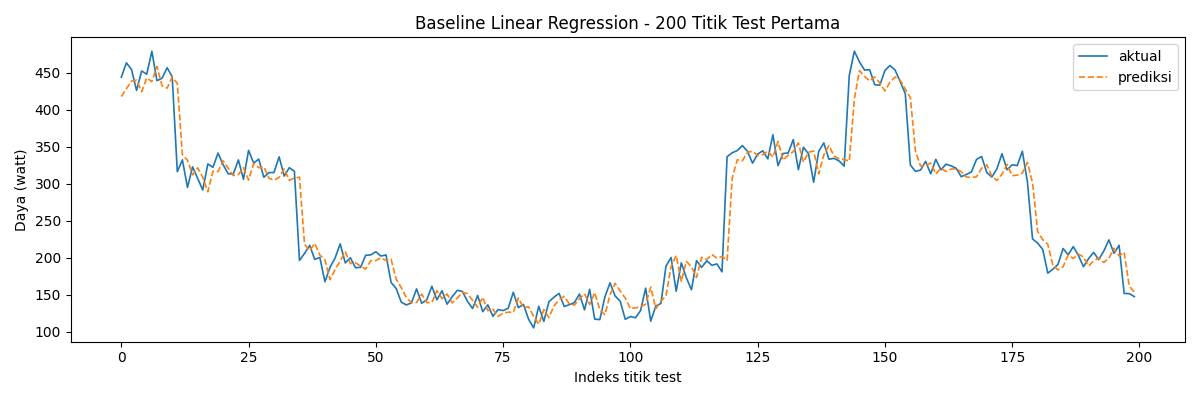

In [5]:
from IPython.display import Image
Image("outputs/figures/baseline_regression_pred.png")

## Penutup

Baseline klasifikasi: accuracy test sekitar 0.99, recall kelas abnormal sekitar 0.84
(confusion matrix menunjukkan sedikit false negative). Baseline regresi: MAE test sekitar
17 watt. Angka-angka ini menjadi patokan untuk model yang lebih kuat pada Hands-on 23-25.

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 19 dalam urutan buku) agar dapat dijadikan panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 8. Langkah kerja yang harus dilakukan pembaca

Tahap 1 — Siapkan dataset klasifikasi
Bangun target normal vs abnormal, buat fitur, lalu split berbasis waktu.

Tahap 2 — Siapkan dataset regresi
Bangun target power_watt_next_1step, buat lag dan rolling, lalu split berbasis
waktu.

Tahap 3 — Latih baseline sederhana
Gunakan:
- Logistic Regression untuk klasifikasi
- Linear Regression untuk regresi

Tahap 4 — Evaluasi metrik dengan benar
- klasifikasi → accuracy, precision, recall, F1, confusion matrix
- regresi → MAE, RMSE

Tahap 5 — Bandingkan sintetik dan nyata
Lihat apakah performa konsisten atau menurun tajam.

Tahap 6 — Simpan hasil
Simpan:

train/validation/test
file prediksi
ringkasan metrik
confusion matrix atau residual sederhana